In [1]:
import pandas as pd
df = pd.read_csv("../data/processed/food_safety_clean (1).csv")

In [2]:
cols = ["sugars_g","saturated_fat_g","salt_g","energy_kcal","fiber_g","additive_count"]
df.groupby("general_verdict")[cols].median()

,sugars_g,saturated_fat_g,salt_g,energy_kcal,fiber_g,additive_count
general_verdict,,,,,,
Avoid,14.0,7.80,0.6980,446.670,3.0,0.0
Limit,4.3,1.80,0.1585,285.000,4.4,0.0
Safe,1.0,0.27,0.0320,177.731,3.5,0.0


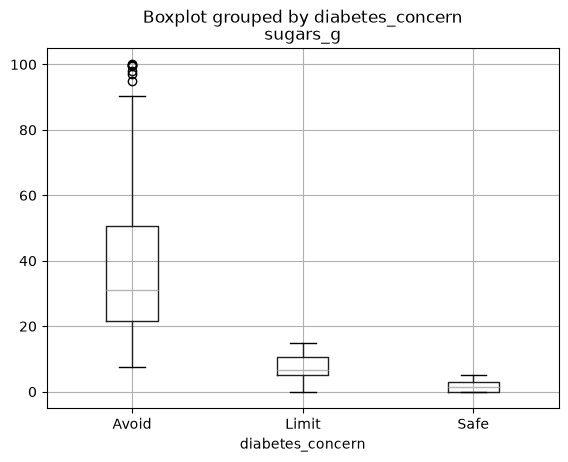

In [3]:
import matplotlib.pyplot as plt
df.boxplot(column="sugars_g", by="diabetes_concern")
plt.show()

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
flags = [c for c in df.columns if c.startswith("has_")] + ["additive_count","n_ingredients"]
print(cross_val_score(DecisionTreeClassifier(max_depth=5), df[flags], df["general_verdict"], cv=5).mean())

0.6126925961641487


In [2]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

df = pd.read_csv("../data/processed/food_safety_clean (1).csv")
y = df["general_verdict"]

flags = [c for c in df.columns if c.startswith("has_")] + ["additive_count", "n_ingredients"]
nutrients = ["sugars_g", "saturated_fat_g", "salt_g", "energy_kcal", "fat_g",
             "carbohydrates_g", "proteins_g"]

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Decision tree":       DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=0),
    "Random forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
    "Gradient boosting":   GradientBoostingClassifier(random_state=0),
}

cv = StratifiedKFold(5, shuffle=True, random_state=0)
rows = []
for fs_name, cols in [("ingredient flags", flags), ("nutrients", nutrients)]:
    for m_name, model in models.items():
        r = cross_validate(model, df[cols], y, cv=cv, scoring=["accuracy", "f1_macro"])
        rows.append({"features": fs_name, "model": m_name,
                     "accuracy": r["test_accuracy"].mean().round(3),
                     "macro_F1": r["test_f1_macro"].mean().round(3)})
pd.DataFrame(rows)

,features,model,accuracy,macro_F1
0,ingredient flags,Baseline (majority),0.461,0.210
1,ingredient flags,Logistic regression,0.596,0.559
2,ingredient flags,Decision tree,0.596,0.535
3,ingredient flags,Random forest,0.592,0.565
4,ingredient flags,Gradient boosting,0.613,0.560
5,nutrients,Baseline (majority),0.461,0.210
6,nutrients,Logistic regression,0.671,0.672
7,nutrients,Decision tree,0.765,0.759
8,nutrients,Random forest,0.847,0.841
9,nutrients,Gradient boosting,0.836,0.827


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

text = df["ingredients_clean"].str.lower()
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)

text_models = {
    "TF-IDF + Logistic":   make_pipeline(tfidf(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "TF-IDF + LinearSVC":  make_pipeline(tfidf(), LinearSVC(class_weight="balanced")),
    "TF-IDF + NaiveBayes": make_pipeline(tfidf(), MultinomialNB()),
}
rows = []
for name, model in text_models.items():
    r = cross_validate(model, text, y, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean().round(3),
                 "macro_F1": r["test_f1_macro"].mean().round(3)})
pd.DataFrame(rows)

,model,accuracy,macro_F1
0,TF-IDF + Logistic,0.726,0.719
1,TF-IDF + LinearSVC,0.720,0.711
2,TF-IDF + NaiveBayes,0.674,0.609


In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

labels = ["Safe", "Limit", "Avoid"]
pred = cross_val_predict(text_models["TF-IDF + Logistic"], text, y, cv=cv)
print(classification_report(y, pred, labels=labels))
print(confusion_matrix(y, pred, labels=labels))
print("Avoid -> Safe rate:", ((y == "Avoid") & (pred == "Safe")).sum() / (y == "Avoid").sum())

              precision    recall  f1-score   support

        Safe       0.70      0.75      0.72       283
       Limit       0.64      0.63      0.64       540
       Avoid       0.80      0.79      0.80       703

    accuracy                           0.73      1526
   macro avg       0.71      0.72      0.72      1526
weighted avg       0.73      0.73      0.73      1526

[[213  60  10]
 [ 73 342 125]
 [ 19 131 553]]
Avoid -> Safe rate: 0.02702702702702703


In [7]:
from sklearn.model_selection import GroupKFold

groups = df["brand_clean"]
pred_g = cross_val_predict(text_models["TF-IDF + Logistic"], text, y,
                           cv=GroupKFold(5), groups=groups)
print(classification_report(y, pred_g, labels=labels))

              precision    recall  f1-score   support

        Safe       0.66      0.78      0.72       283
       Limit       0.64      0.59      0.61       540
       Avoid       0.79      0.79      0.79       703

    accuracy                           0.71      1526
   macro avg       0.70      0.72      0.71      1526
weighted avg       0.71      0.71      0.71      1526



In [8]:
model = text_models["TF-IDF + Logistic"].fit(text, y)
vec = model.named_steps["tfidfvectorizer"]
clf = model.named_steps["logisticregression"]
names = vec.get_feature_names_out()

for i, cls in enumerate(clf.classes_):      # classes_ is alphabetical: Avoid, Limit, Safe
    top = clf.coef_[i].argsort()[-15:][::-1]
    print(f"\nTop words pushing toward {cls}:")
    print([names[j] for j in top])


Top words pushing toward Avoid:
['sugar', 'butter', 'ins', 'milk fat', 'and', 'jaggery', 'refined', 'fat', 'glucose', 'vegetable', 'honey', 'hydrogenated', 'palm', 'oil', 'ii']

Top words pushing toward Limit:
['sunflower', 'raisins', 'dates', 'oil', 'sunflower oil', 'cashew nuts', 'cashews', 'nutmeg', 'flour atta', 'pumpkin', 'peanuts 100', 'peanuts', 'salt', 'gluten', 'mustard oil']

Top words pushing toward Safe:
['rice', 'wheat', 'culture', 'oats', 'black tea', 'water', 'basmati', 'rolled', 'rolled oats', 'turmeric', 'chana', 'tea', 'poha', 'active', 'barley']


In [9]:
bad = df[(y == "Avoid") & (pred == "Safe")]
bad[["product_name", "ingredients_clean", "sugars_g", "salt_g", "reasons_general"]]

,product_name,ingredients_clean,sugars_g,salt_g,reasons_general
28,South Indian Filter Coffee,ROAST AND GROUND COFFEE & CHICORY COFFEE BLEND...,10.400,0.182,Nutri-Score E
170,BRITANNIA marie GOLD,Refin,20.200,0.732,high sat fat; Nutri-Score E
486,coconut water,Water and Coconut Water Concentrate Equivalent...,4.900,52.500,high salt; Nutri-Score E
538,Chitale Coffee,"Toned Milk, Sugar Coffee(0.5%), Stabilizer(E-401)",14.500,0.148,high sugar; Nutri-Score E; ultra-processed (NO...
579,Organic Jaggery Powder,Organic Jaggery Powder,90.300,0.026,high sugar; Nutri-Score E
657,cold pressed groundnut oil,"Cold Pressed Groundnut Oil, Vitamin A & D",0.000,0.000,high sat fat; Nutri-Score E
666,Eat Better Co Coffee Almond Laddoos,"Dates, Almonds(33%), Oats, Coconut, Coffee (2%...",27.200,0.174,high sat fat; high sugar; Nutri-Score D
669,Amba Sauce,"Sliced Mango, Water, Salt, Vinegar (Water+Acet...",0.000,7.500,high salt; Nutri-Score D; ultra-processed (NOV...
695,Glucose-D,"Glucose (99.4%), Calcium Phosphates (0.6%), Vi...",90.000,0.038,high sugar; ultra-processed (NOVA 4)
699,Amulspray Infant Milk Food,"Partly skimmed milk, sugar, minerals, vitamins.",50.000,0.225,high sat fat; high sugar
